# LM27 Lab — Portfolio Return and Risk

Companion notebook to **From Calculus to Kelly, LM27**. It rebuilds the module's exhibits and computational examples from E5's raw closes, the through case's per-date targets for R1 and R2, and the sector closes of U28. It also checks the widget's starting values, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | E5's two frames from the raw closes, distributions and split, checked against the derived frames (Example 4, Problem 11) |
| 2 | The June 2025 span (Example 1) and the buy-and-hold drift (Exhibit 2) |
| 3 | The wealth recursion (27.2): R1 and R2 from their targets against their net wealth paths, Example 2, Example 3 and Exhibit 3 (Problem 12) |
| 4 | Asynchronous closes: correlations by frequency with both standard errors and the funds' kurtosis (Exhibit 4, Example 5) |
| 5 | $\hat\Sigma$, the means and the correlations (Exhibit 5), R1's and R2's $\mu_p$, $s_p$ and ratio (27.7) (Example 6), and the knowledge checks of Sections 5 and 9 |
| 6 | Risk splits (Example 7, Exhibit 6, Exhibit 1), the slope check, the switch (Example 8) and the widget's starting values |
| 7 | R1's shares in the 92 windows (Exhibit 7, Example 9) |
| 8 | U28's factor split (Example 10, Exhibit 8) and LM9's drift |
| 9 | Practice problems 10, 11 and 12, and the module's code block |
| 10 | Extension: R2's risk shares in the 92 windows |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds these files, and the notebook reads nothing outside `data/`:

- `0050__2016-12-01__2026-10-08.csv` and the files of 00646, 00679B, 00635U and 00642U: `date, open, max, min, close, spread, volume` from FinMind `TaiwanStockPrice`; `0050_dividends__…` and `00679B_dividends__…`: the cash distributions (`TaiwanStockDividendResult`); `splits__…`: every split in `TaiwanStockSplitPrice`, among them 0050's of 18 June 2025.
- `taiex_tr.csv`: the TAIEX total-return closes, whose dates are TR23's calendar.
- `e5_estimation.csv` and `e5_wealth.csv`: E5's two frames in long form (`base, date, fund, R`, and `traded` in the wealth frame), built by `data/vol5_series.py`.
- `rule_targets_R1_R2.csv`: R1's and R2's trades (`rule, signal, trade`, the five target exposures, `exposure, turnover, cost`); `rule_wealth_net_R1_R2.csv`: their net wealth after each day's trade. Both are built by `data/vol5_rules.py`.
- `sectors_close_raw.csv` and `sectors_close_repairs.csv`: the closes of TAIEX and the sector indices, and the 561 closes that FinMind copied from another date or series with their official 13:30:00 values (on FinMind's free plan the repair values are empty: Part 8 then drops those closes and its numbers differ slightly).

**Conventions (as in the module).**

- E5: simple total returns $(P_t+D_t)/P_{t-1}-1$, on a split day $(P_t+D_t)/(P_{t-1}/4)-1$. Estimation frame: the dates on which every fund has a one-session return, $T=2{,}362$; wealth frame: every TR23 session after the base close, 2,368, a halted fund earning 0 until it trades again.
- Years are calendar days / 365.25 from the close before the first return to the last close; $A=T/\text{years}$. Moments divide by $T$ (`ddof=0`).
- Weeks are ISO weeks (keys ISO year, ISO week), months calendar months; the first and last of each are dropped, complete or not. Weeks are annualized by the weeks with a session over their years, months by 12.
- Costs: commission 0.1425% on each side, tax 0.1% on sales of every fund but 00679B; cash at $r_f=1.5\%$ a year, $r_f/A_{\mathrm w}$ a session.
- Counts against a threshold use the guard `1e-12`.

In [1]:
import math
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

DATA = Path("data")
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
J = {s: i for i, s in enumerate(FUNDS)}
W5 = "2016-12-01__2026-10-08"
LAST = "2026-10-08"
COMM = 0.001425
TAX = {"0050": 0.001, "00646": 0.001, "00679B": 0.0, "00635U": 0.001, "00642U": 0.001}
RF, SPREAD = 0.015, 0.02
WINDOW = 504
EPS = 1e-12
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(12)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed, u28=False):
    # print a value next to the module's printed value and assert that they agree (U28's values only with every
    # copied close repaired: see Part 8)
    got = format(value, fmt)
    differs = got != printed
    note = "" if not differs else ("   (differs: closes were dropped)" if u28 and not FULL_DATA else "   MISMATCH")
    print(f"{label}: {got}   [book: {printed}]{note}")
    assert not differs or (u28 and not FULL_DATA), (label, got, printed)


def cov0(x):
    # sample covariance with divisor T
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]


def split(S, w):
    # (s_p, beta_{i,p}, MRC, RC, shares) of weights w under the covariance matrix S, (27.5)-(27.6)
    Sw = S @ w
    v = float(w @ Sw)
    sp = math.sqrt(v)
    return sp, Sw / v, Sw / sp, w * Sw / sp, w * Sw / v


def se_rho(x, y):
    # correlation, normal-theory SE (1 - rho^2)/sqrt(T) and plug-in SE sd(L_t)/sqrt(T) (LM20, Problem 6)
    xs, ys = (x - x.mean()) / x.std(ddof=0), (y - y.mean()) / y.std(ddof=0)
    r = float(np.mean(xs * ys))
    L = xs * ys - r / 2 * (xs**2 + ys**2)
    return r, (1 - r * r) / math.sqrt(len(x)), float(L.std(ddof=0)) / math.sqrt(len(x))


FULL_DATA = True                  # set in Part 8 from the repair file

## Part 1 — E5's two frames from the raw files (Problem 11)

A fund's total return on date $t$ divides its close plus any distribution by its previous close, restated per current share on a split day. The **estimation frame** keeps the dates on which every fund has a one-session return (a close on $t$ and on the previous TR23 date). The **wealth frame** keeps every TR23 session after the base close: a fund without a close earns 0, and its return from its last close is booked on the day it trades again. Example 4 explains the six dates of June 2025 that only the wealth frame holds.

In [2]:
cal = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"date": pl.String})["date"].to_list()   # TR23's dates
spl = pl.read_csv(DATA / f"splits__{W5}.csv", schema_overrides={"date": pl.String, "stock_id": pl.String})


def closes(sym):
    df = pl.read_csv(DATA / f"{sym}__{W5}.csv", schema_overrides={"date": pl.String})
    return dict(zip(df["date"].to_list(), df["close"].to_list()))


def dividends(sym):
    f = DATA / f"{sym}_dividends__{W5}.csv"
    if not f.exists():
        return {}
    df = pl.read_csv(f, schema_overrides={"date": pl.String})
    return dict(zip(df["date"].to_list(), df["cash_dividend"].to_list()))


def splits(sym):
    s = spl.filter(pl.col("stock_id") == pl.lit(sym))
    return {d: round(b / a) for d, b, a in s.select("date", "before_price", "after_price").iter_rows()}


def returns(sym):
    # (one-session returns, returns from the last close), keyed by date
    px, div, spt = closes(sym), dividends(sym), splits(sym)
    one, own, last = {}, {}, None
    for d0, d1 in zip(cal[:-1], cal[1:]):
        if d0 in px:
            last = d0
        if d1 not in px or last is None:
            continue
        r = (px[d1] + div.get(d1, 0.0)) / (px[last] / spt.get(d1, 1.0)) - 1
        own[d1] = r
        if last == d0:
            one[d1] = r
    return one, own


print("0050's splits:", splits("0050"))
per = [returns(s) for s in FUNDS]
base = min(set.intersection(*[set(closes(s)) for s in FUNDS]))
wdates = [d for d in cal if base < d <= LAST]
edates = [d for d in wdates if all(d in one for one, _ in per)]
X = np.array([[one[d] for one, _ in per] for d in edates])
Wm = np.array([[own.get(d, 0.0) for _, own in per] for d in wdates])
traded = np.array([[d in own for _, own in per] for d in wdates])
days = (date.fromisoformat(LAST) - date.fromisoformat(base)).days
YEARS = days / 365.25
T = len(edates)
A = T / YEARS
A_W = len(wdates) / YEARS
print(f"base close {base}; {days} calendar days, {YEARS:.4f} years")
show("estimation frame T", T, ",d", "2,362")
show("wealth frame sessions", len(wdates), ",d", "2,368")
show("A", A, ".3f", "242.951")
show("A_w", A_W, ".3f", "243.569")
only_w = [d for d in wdates if d not in set(edates)]
print("dates in the wealth frame only:", only_w)

# against the derived frames that data/make_lab_data.py wrote
est = pl.read_csv(DATA / "e5_estimation.csv", schema_overrides={"date": pl.String, "fund": pl.String, "base": pl.String})
wfr = pl.read_csv(DATA / "e5_wealth.csv", schema_overrides={"date": pl.String, "fund": pl.String, "base": pl.String})
Xd = est.pivot(on="fund", index="date", values="R").sort("date")
Wd = wfr.pivot(on="fund", index="date", values="R").sort("date")
Td = wfr.pivot(on="fund", index="date", values="traded").sort("date")
assert Xd["date"].to_list() == edates and Wd["date"].to_list() == wdates
print("largest difference from the derived frames:",
      float(np.abs(Xd.select(FUNDS).to_numpy() - X).max()), float(np.abs(Wd.select(FUNDS).to_numpy() - Wm).max()),
      "| traded flags equal:", bool((Td.select(FUNDS).to_numpy() == traded).all()))
iw = wdates.index("2025-06-18")
show("0050 on 18 June 2025, %", 100 * Wm[iw, J["0050"]], ".3f", "0.864")
gw, ge = np.prod(1 + Wm, axis=0), np.prod(1 + X, axis=0)
show("00642U's growth factor, wealth frame", gw[J["00642U"]], ".3f", "1.593")
show("00642U's growth factor, estimation frame", ge[J["00642U"]], ".3f", "1.412")

0050's splits: {'2025-06-18': 4}
base close 2017-01-17; 3551 calendar days, 9.7221 years
estimation frame T: 2,362   [book: 2,362]
wealth frame sessions: 2,368   [book: 2,368]
A: 242.951   [book: 242.951]
A_w: 243.569   [book: 243.569]
dates in the wealth frame only: ['2025-06-11', '2025-06-12', '2025-06-13', '2025-06-16', '2025-06-17', '2025-06-18']
largest difference from the derived frames: 0.0 0.0 | traded flags equal: True
0050 on 18 June 2025, %: 0.864   [book: 0.864]
00642U's growth factor, wealth frame: 1.593   [book: 1.593]
00642U's growth factor, estimation frame: 1.412   [book: 1.412]


## Part 2 — The June 2025 span and the drift (Example 1, Exhibit 2)

A book bought at a fifth each at the close of 10 June 2025 earns the average of the funds' simple returns over the span, by (27.1) applied once. The average of their log returns understates it, (1.14). R1 itself held weights that had drifted since its trade of 2 June. Then the drift of a book bought at a fifth each on 4 March 2019, R1's first purchase, and never traded again.

returns over the span, %: [ 0.864 -1.689 -0.792  2.226 12.816]
1/N over the span, %: 2.685   [book: 2.685]
mean log return: 0.02524   [book: 0.02524]
exp(mean log) - 1, %: 2.56   [book: 2.56]
R1 over the span, %: 2.73   [book: 2.73]
KC: 00642U's weight on 18 June, %: 21.97   [book: 21.97]
end weights, %: ['48.619', '19.734', '5.422', '14.513', '11.712']
0050 at the end, %: 48.6   [book: 48.6]
0050: low 19.1% (2019-08-15), high 49.1% (2026-07-01)
00646: low 16.5% (2020-03-23), high 27.1% (2024-11-28)
00679B: low 5.4% (2026-10-07), high 28.0% (2020-03-23)
00635U: low 14.4% (2026-10-06), high 25.5% (2026-01-29)
00642U: low 7.0% (2020-11-02), high 21.3% (2019-04-23)
0050's low, %: 19.1   [book: 19.1]
0050's high, %: 49.1   [book: 49.1]
00679B's high, %: 28.0   [book: 28.0]
00642U's high, %: 21.3   [book: 21.3]
00642U's low, %: 7.0   [book: 7.0]


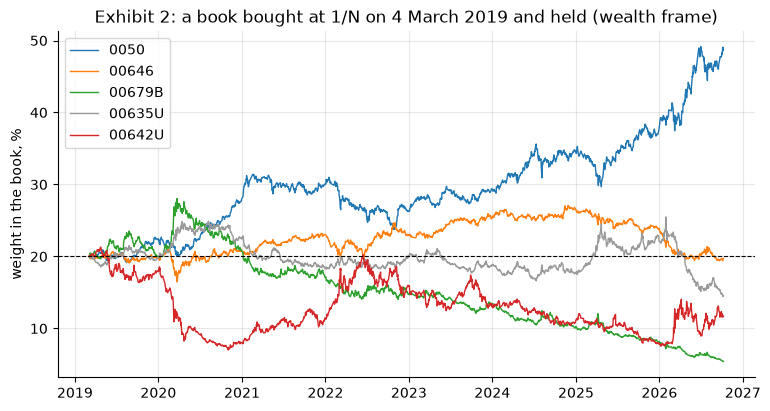

In [3]:
i0, i1 = wdates.index("2025-06-10"), wdates.index("2025-06-18")
G = np.prod(1 + Wm[i0 + 1:i1 + 1], axis=0)
print("returns over the span, %:", np.round(100 * (G - 1), 3))
show("1/N over the span, %", 100 * (G.mean() - 1), ".3f", "2.685")
show("mean log return", float(np.log(G).mean()), ".5f", "0.02524")
show("exp(mean log) - 1, %", 100 * (math.exp(float(np.log(G).mean())) - 1), ".2f", "2.56")
net = pl.read_csv(DATA / "rule_wealth_net_R1_R2.csv", schema_overrides={"date": pl.String})
r1 = net.filter(pl.col("rule") == pl.lit("R1")).sort("date")
w1p = dict(zip(r1["date"].to_list(), r1["wealth"].to_list()))
show("R1 over the span, %", 100 * (w1p["2025-06-18"] / w1p["2025-06-10"] - 1), ".2f", "2.73")
show("KC: 00642U's weight on 18 June, %", 100 * 0.2 * G[J["00642U"]] / (0.2 * G).sum(), ".2f", "21.97")

ib = wdates.index("2019-03-04")
g = np.cumprod(1 + Wm[ib + 1:], axis=0)
wbh = g / g.sum(axis=1, keepdims=True)
dbh = wdates[ib + 1:]
print("end weights, %:", [f"{100 * x:.3f}" for x in wbh[-1]])
show("0050 at the end, %", 100 * wbh[-1, 0], ".1f", "48.6")
for s in FUNDS:
    j = J[s]
    print(f"{s}: low {100 * wbh[:, j].min():.1f}% ({dbh[int(wbh[:, j].argmin())]}), "
          f"high {100 * wbh[:, j].max():.1f}% ({dbh[int(wbh[:, j].argmax())]})")
show("0050's low, %", 100 * wbh[:, 0].min(), ".1f", "19.1")
show("0050's high, %", 100 * wbh[:, 0].max(), ".1f", "49.1")
show("00679B's high, %", 100 * wbh[:, J["00679B"]].max(), ".1f", "28.0")
show("00642U's high, %", 100 * wbh[:, J["00642U"]].max(), ".1f", "21.3")
show("00642U's low, %", 100 * wbh[:, J["00642U"]].min(), ".1f", "7.0")

fig, ax = plt.subplots()
dd = [date.fromisoformat(d) for d in dbh]
for s in FUNDS:
    ax.plot(dd, 100 * wbh[:, J[s]], lw=1, label=s, color="0.6" if s == "00635U" else None)
ax.axhline(20, ls="--", c="k", lw=0.8)
ax.set_ylabel("weight in the book, %")
ax.set_title("Exhibit 2: a book bought at 1/N on 4 March 2019 and held (wealth frame)")
ax.legend()
plt.show()

## Part 3 — The wealth recursion (27.2) (Problem 12)

From cash of 1, a rule trades at its trade dates to its targets. The post-trade wealth solves $W_t=W^{\mathrm{pre}}_t-\operatorname{cost}(W_t\mathbf f_t-W^{\mathrm{pre}}_t\mathbf w^{\mathrm{drift}}_t)$, found here by iteration (the map contracts, Deep Dive 1). Cash earns $r_f/A_{\mathrm w}$ a session; a negative balance would pay $r_f$ plus 2 points (LM31's R8; R1 and R2 never borrow). The cell runs R1 and R2 and prints only the largest difference from their net wealth paths, not the paths.

In [4]:
tg = pl.read_csv(DATA / "rule_targets_R1_R2.csv", schema_overrides={"signal": pl.String, "trade": pl.String})
taxv = np.array([TAX[s] for s in FUNDS])


def run_rule(rule):
    t = tg.filter(pl.col("rule") == pl.lit(rule)).sort("trade")
    targets = {row[0]: np.array(row[1:]) for row in t.select("trade", *FUNDS).iter_rows()}
    i0 = wdates.index(t["trade"][0])
    h, c, path, trades = np.zeros(len(FUNDS)), 1.0, [], []
    for i in range(i0, len(wdates)):
        if i > i0:
            h = h * (1 + Wm[i])
            c *= 1 + (RF if c >= 0 else RF + SPREAD) / A_W
        W = float(h.sum() + c)
        f = targets.get(wdates[i])
        if f is not None:
            drift, Wn, cost = h / W, W, 0.0
            for _ in range(100):
                delta = Wn * f - h
                cost = COMM * float(np.abs(delta).sum()) + float(taxv @ np.clip(-delta, 0, None))
                new = W - cost
                if abs(new - Wn) < 1e-15 * W:
                    break
                Wn = new
            trades.append({"trade": wdates[i], "W_pre": W, "W_post": Wn, "drift": drift, "f": f,
                           "TO": 0.5 * float(np.abs(f - drift).sum()), "cost": cost / W})
            h, c, W = Wn * f, Wn * (1 - float(f.sum())), Wn
        path.append(W)
    return wdates[i0:], np.array(path), trades


paths = {}
for rule in ("R1", "R2"):
    d_, p_, tr_ = run_rule(rule)
    ref = net.filter(pl.col("rule") == pl.lit(rule)).sort("date")
    assert ref["date"].to_list() == d_
    paths[rule] = (d_, p_, tr_)
    print(f"{rule}: {len(tr_)} trades; largest |difference| from the net wealth path "
          f"{float(np.abs(ref['wealth'].to_numpy() - p_).max()):.1e}")

tr1 = paths["R1"][2]
t0 = tr1[0]
show("first purchase: W after the trade", t0["W_post"], ".6f", "0.998577")
show("first purchase: cost, % of W_pre", 100 * t0["cost"], ".4f", "0.1423")
show("first purchase: turnover", t0["TO"], ".1f", "0.5")
reb = tr1[1:]
big = max(reb, key=lambda x: x["TO"])
print(f"{len(reb)} rebalances; the largest one-way turnover on {big['trade']}")
show("1 April 2026: turnover, %", 100 * big["TO"], ".3f", "8.058")
print("drifted weights, %:", [f"{100 * x:.3f}" for x in big["drift"]])
approx = 2 * COMM * big["TO"] + float(taxv @ np.clip(big["drift"] - big["f"], 0, None))
show("1 April 2026: cost by (27.3), %", 100 * approx, ".5f", "0.03102")
show("1 April 2026: exact cost, %", 100 * big["cost"], ".5f", "0.03100")

B = 1e7                                                   # a book of NT$10 million before the trade (scale-free)
x = (big["W_post"] * big["f"] - big["W_pre"] * big["drift"]) / big["W_pre"]
x3 = pl.DataFrame({"fund": FUNDS, "before": np.round(B * big["drift"]), "trade": np.round(B * x),
                   "after": np.round(B * big["W_post"] / big["W_pre"] * big["f"]),
                   "commission": np.round(B * COMM * np.abs(x)), "tax": np.round(B * taxv * np.clip(-x, 0, None))}
                  ).with_columns(pl.exclude("fund").cast(pl.Int64))
print(x3)
print(x3.select(pl.all().exclude("fund").sum()))
show("Exhibit 3: cost, NT$", B * big["cost"], ",.0f", "3,100")

R1: 92 trades; largest |difference| from the net wealth path 0.0e+00
R2: 92 trades; largest |difference| from the net wealth path 0.0e+00
first purchase: W after the trade: 0.998577   [book: 0.998577]
first purchase: cost, % of W_pre: 0.1423   [book: 0.1423]
first purchase: turnover: 0.5   [book: 0.5]
91 rebalances; the largest one-way turnover on 2026-04-01
1 April 2026: turnover, %: 8.058   [book: 8.058]
drifted weights, %: ['17.954', '18.611', '18.697', '16.680', '28.058']
1 April 2026: cost by (27.3), %: 0.03102   [book: 0.03102]
1 April 2026: exact cost, %: 0.03100   [book: 0.03100]
shape: (5, 6)
┌────────┬─────────┬─────────┬─────────┬────────────┬─────┐
│ fund   ┆ before  ┆ trade   ┆ after   ┆ commission ┆ tax │
│ ---    ┆ ---     ┆ ---     ┆ ---     ┆ ---        ┆ --- │
│ str    ┆ i64     ┆ i64     ┆ i64     ┆ i64        ┆ i64 │
╞════════╪═════════╪═════════╪═════════╪════════════╪═════╡
│ 0050   ┆ 1795428 ┆ 203952  ┆ 1999380 ┆ 291        ┆ 0   │
│ 00646  ┆ 1861080 ┆ 138300  ┆ 

## Part 4 — Asynchronous closes (Exhibit 4, Example 5)

Weekly and monthly returns compound the estimation frame's daily returns within ISO weeks and calendar months; the first and last week and month are dropped, complete or not. A correlation's normal-theory standard error is $(1-\hat\rho^2)/\sqrt T$; the plug-in one is LM20's $\operatorname{sd}(L_t)/\sqrt T$. Both assume independent periods, and the plug-in one needs finite fourth moments, so the cell prints each fund's raw kurtosis (19.3).

weeks: 500   [book: 500]
months: 116   [book: 116]
weekly years from the close of 2017-01-20 to that of 2026-10-02: 9.6975
weekly A: 51.56   [book: 51.56]
shape: (15, 5)
┌───────────────┬───────────┬─────────┬───────────┬────────────┐
│ pair          ┆ frequency ┆ rho     ┆ SE normal ┆ SE plug-in │
│ ---           ┆ ---       ┆ ---     ┆ ---       ┆ ---        │
│ str           ┆ str       ┆ f64     ┆ f64       ┆ f64        │
╞═══════════════╪═══════════╪═════════╪═══════════╪════════════╡
│ 0050-00646    ┆ daily     ┆ 0.5988  ┆ 0.0132    ┆ 0.0248     │
│ 0050-00646    ┆ weekly    ┆ 0.588   ┆ 0.0293    ┆ 0.0309     │
│ 0050-00646    ┆ monthly   ┆ 0.5521  ┆ 0.0645    ┆ 0.0806     │
│ 0050-00679B   ┆ daily     ┆ -0.1054 ┆ 0.0203    ┆ 0.0397     │
│ 0050-00679B   ┆ weekly    ┆ -0.0232 ┆ 0.0447    ┆ 0.0531     │
│ 0050-00679B   ┆ monthly   ┆ -0.0132 ┆ 0.0928    ┆ 0.095      │
│ 0050-00635U   ┆ daily     ┆ 0.1801  ┆ 0.0199    ┆ 0.0284     │
│ 0050-00635U   ┆ weekly    ┆ 0.2284  ┆ 0.0424    

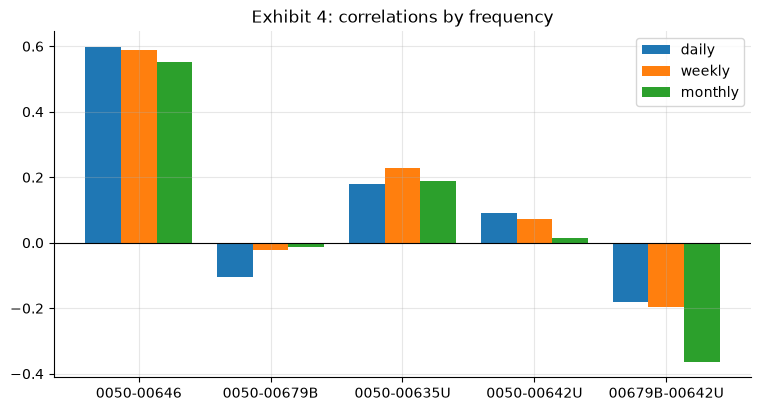

In [5]:
d = pl.col("date").str.to_date()


def compound(keys):
    g = (est.with_columns(*keys).group_by("fund", *[k.meta.output_name() for k in keys])
         .agg((pl.col("R") + 1).product() - 1, pl.col("date").max().alias("last")))
    wide = g.pivot(on="fund", index=[k.meta.output_name() for k in keys] + ["last"], values="R").sort("last")
    return wide.slice(1, wide.height - 2)                # drop the first and last period


wk = compound([d.dt.iso_year().alias("y"), d.dt.week().alias("k")])
mo = compound([d.dt.year().alias("y"), d.dt.month().alias("m")])
Xw, Xm = wk.select(FUNDS).to_numpy(), mo.select(FUNDS).to_numpy()
show("weeks", wk.height, "d", "500")
show("months", mo.height, "d", "116")
c_before = max(dd for dd in edates if dd < wk["last"][0] and date.fromisoformat(dd).isocalendar()[:2]
               != date.fromisoformat(wk["last"][0]).isocalendar()[:2])
c_last = wk["last"][-1]
yrs_w = (date.fromisoformat(c_last) - date.fromisoformat(c_before)).days / 365.25
A_WEEK = wk.height / yrs_w
print(f"weekly years from the close of {c_before} to that of {c_last}: {yrs_w:.4f}")
show("weekly A", A_WEEK, ".2f", "51.56")

FRQ = {"daily": (X, A), "weekly": (Xw, A_WEEK), "monthly": (Xm, 12.0)}
pairs = [(0, j) for j in range(1, 5)] + [(J["00679B"], J["00642U"])]
rows = []
for a, b in pairs:
    for nm, (x, _) in FRQ.items():
        r, sn, sp_ = se_rho(x[:, a], x[:, b])
        rows.append({"pair": f"{FUNDS[a]}-{FUNDS[b]}", "frequency": nm, "rho": r, "SE normal": sn, "SE plug-in": sp_})
cor = pl.DataFrame(rows)
print(cor.with_columns(pl.col("rho", "SE normal", "SE plug-in").round(4)))
get = {(r["pair"], r["frequency"]): r for r in rows}
show("0050-00679B daily", get["0050-00679B", "daily"]["rho"], ".3f", "-0.105")
show("0050-00679B monthly", get["0050-00679B", "monthly"]["rho"], ".3f", "-0.013")
show("0050-00646 weekly", get["0050-00646", "weekly"]["rho"], ".3f", "0.588")
show("00679B-00642U monthly", get["00679B-00642U", "monthly"]["rho"], ".2f", "-0.36")
gap = abs(get["00679B-00642U", "daily"]["rho"] - get["00679B-00642U", "monthly"]["rho"])
show("00679B-00642U daily-monthly gap", gap, ".4f", "0.1815")
show("  in monthly normal-theory SEs", gap / get["00679B-00642U", "monthly"]["SE normal"], ".1f", "2.3")
show("  in monthly plug-in SEs", gap / get["00679B-00642U", "monthly"]["SE plug-in"], ".1f", "2.0")
for nm, (x, _) in FRQ.items():
    k = ((x - x.mean(axis=0)) ** 4).mean(axis=0) / x.var(axis=0, ddof=0) ** 2
    print(f"raw kurtosis (19.3), {nm}:", {s: round(float(v), 1) for s, v in zip(FUNDS, k)})
w1 = np.full(5, 0.2)
for nm, (x, a_) in FRQ.items():
    sp_, _, _, _, sh_ = split(cov0(x), w1)
    print(f"R1, {nm}: volatility {100 * sp_ * math.sqrt(a_):.2f}%, 00642U's share {100 * sh_[J['00642U']]:.1f}%")

fig, ax = plt.subplots()
xs = np.arange(len(pairs))
for k, nm in enumerate(FRQ):
    ax.bar(xs + (k - 1) * 0.27, [get[f"{FUNDS[a]}-{FUNDS[b]}", nm]["rho"] for a, b in pairs], 0.27, label=nm)
ax.set_xticks(xs, [f"{FUNDS[a]}-{FUNDS[b]}" for a, b in pairs])
ax.axhline(0, c="k", lw=0.8)
ax.set_title("Exhibit 4: correlations by frequency")
ax.legend()
plt.show()

The statements of Example 5 are scoped to the five pairs shown. Over all ten pairs, run the same loop: 00646–00679B has a larger daily–weekly gap than 0050–00679B, and 00635U–00642U a second daily–monthly gap of two monthly normal-theory standard errors.

In [6]:
ten = []
for a in range(5):
    for b in range(a + 1, 5):
        rd, _, _ = se_rho(X[:, a], X[:, b])
        rw, sw_n, _ = se_rho(Xw[:, a], Xw[:, b])
        rm, sm_n, _ = se_rho(Xm[:, a], Xm[:, b])
        ten.append({"pair": f"{FUNDS[a]}-{FUNDS[b]}", "daily-weekly in weekly SEs": abs(rd - rw) / sw_n,
                    "daily-monthly in monthly SEs": abs(rd - rm) / sm_n})
print(pl.DataFrame(ten).with_columns(pl.col("daily-weekly in weekly SEs", "daily-monthly in monthly SEs").round(2)))

shape: (10, 3)
┌───────────────┬────────────────────────────┬──────────────────────────────┐
│ pair          ┆ daily-weekly in weekly SEs ┆ daily-monthly in monthly SEs │
│ ---           ┆ ---                        ┆ ---                          │
│ str           ┆ f64                        ┆ f64                          │
╞═══════════════╪════════════════════════════╪══════════════════════════════╡
│ 0050-00646    ┆ 0.37                       ┆ 0.72                         │
│ 0050-00679B   ┆ 1.84                       ┆ 0.99                         │
│ 0050-00635U   ┆ 1.14                       ┆ 0.08                         │
│ 0050-00642U   ┆ 0.43                       ┆ 0.84                         │
│ 00646-00679B  ┆ 1.86                       ┆ 0.33                         │
│ 00646-00635U  ┆ 1.0                        ┆ 1.02                         │
│ 00646-00642U  ┆ 0.54                       ┆ 0.22                         │
│ 00679B-00635U ┆ 0.89                       ┆ 0.

## Part 5 — Means, variances and diversification (Exhibit 5, Example 6)

(27.4) gives $\mu_p=\mathbf w^{\top}\boldsymbol\mu$ and $s_p^2=\mathbf w^{\top}\hat\Sigma\mathbf w$, annualized with $A$. The ratio (27.7) is the weighted average volatility over the book's.

In [7]:
SA = A * cov0(X)
vol = np.sqrt(np.diag(SA))
mu = A * X.mean(axis=0)
C = SA / np.outer(vol, vol)
print(pl.DataFrame({"fund": FUNDS, "mean %": np.round(100 * mu, 2), "volatility %": np.round(100 * vol, 2)}))
print(pl.DataFrame(np.round(C, 2), schema=FUNDS).insert_column(0, pl.Series("fund", FUNDS)))
w2 = np.array([0.4, 0.2, 0.3, 0.1, 0.0])
for nm, w in (("R1", w1), ("R2", w2)):
    sp_ = math.sqrt(float(w @ SA @ w))
    print(f"{nm}: mu_p {100 * float(w @ mu):.2f}%, s_p {100 * sp_:.2f}%, weighted average volatility "
          f"{100 * float(w @ vol):.2f}%, ratio (27.7) {float(w @ vol) / sp_:.2f}")
sp1 = math.sqrt(float(w1 @ SA @ w1))
show("R1's mu_p, %", 100 * float(w1 @ mu), ".2f", "11.57")
show("R2's mu_p, %", 100 * float(w2 @ mu), ".2f", "13.27")
show("R1's s_p, %", 100 * sp1, ".2f", "11.49")
show("R1's variance terms, % of the variance", 100 * float((w1**2 * np.diag(SA)).sum()) / sp1**2, ".1f", "76.4")
lam = np.linalg.eigvalsh(SA)
show("KC 5: lower bound (%^2)", 1e4 * lam[0] / 5, ".2f", "23.61")
show("KC 5: upper bound (%^2)", 1e4 * lam[-1] / 5, ".2f", "285.98")
show("KC 9: np.cov's default factor", math.sqrt(T / (T - 1)), ".6f", "1.000212")
show("KC 9: R1 with np.cov's default, %", 100 * math.sqrt(float(w1 @ (A * np.cov(X, rowvar=False)) @ w1)), ".3f",
     "11.495")

shape: (5, 3)
┌────────┬────────┬──────────────┐
│ fund   ┆ mean % ┆ volatility % │
│ ---    ┆ ---    ┆ ---          │
│ str    ┆ f64    ┆ f64          │
╞════════╪════════╪══════════════╡
│ 0050   ┆ 24.16  ┆ 20.1         │
│ 00646  ┆ 14.87  ┆ 16.12        │
│ 00679B ┆ -0.97  ┆ 13.49        │
│ 00635U ┆ 9.26   ┆ 16.6         │
│ 00642U ┆ 10.53  ┆ 37.43        │
└────────┴────────┴──────────────┘
shape: (5, 6)
┌────────┬───────┬───────┬────────┬────────┬────────┐
│ fund   ┆ 0050  ┆ 00646 ┆ 00679B ┆ 00635U ┆ 00642U │
│ ---    ┆ ---   ┆ ---   ┆ ---    ┆ ---    ┆ ---    │
│ str    ┆ f64   ┆ f64   ┆ f64    ┆ f64    ┆ f64    │
╞════════╪═══════╪═══════╪════════╪════════╪════════╡
│ 0050   ┆ 1.0   ┆ 0.6   ┆ -0.11  ┆ 0.18   ┆ 0.09   │
│ 00646  ┆ 0.6   ┆ 1.0   ┆ -0.08  ┆ 0.09   ┆ 0.2    │
│ 00679B ┆ -0.11 ┆ -0.08 ┆ 1.0    ┆ 0.18   ┆ -0.18  │
│ 00635U ┆ 0.18  ┆ 0.09  ┆ 0.18   ┆ 1.0    ┆ 0.02   │
│ 00642U ┆ 0.09  ┆ 0.2   ┆ -0.18  ┆ 0.02   ┆ 1.0    │
└────────┴───────┴───────┴────────┴────────┴───

## Part 6 — Risk splits, the slope check and the switch (Example 7, Exhibit 6, Example 8)

(27.5)–(27.6): $\Cov(R_i,R_p)=(\hat\Sigma\mathbf w)_i$, $\beta_{i,p}$, $\mathrm{MRC}_i$, $\mathrm{RC}_i$ and the shares $w_i\beta_{i,p}$, which sum to 1. The stand-alone split and the variance terms are printed beside them; only Euler's parts add up to $s_p$. The OLS slope of $w_iR_{i,t}$ on $R_{p,t}$ equals the share. (10.9) gives the exact effect of a switch. The last lines check the widget's first draw: R1 at the daily matrix.

shape: (5, 8)
┌────────┬────────────────┬───────┬───────┬───────────┬────────────────┬────────────────┬──────────┐
│ fund   ┆ A cov(R_i,R_p) ┆ beta  ┆ MRC % ┆ RC points ┆ Euler share %  ┆ stand-alone %  ┆ variance │
│ ---    ┆ %^2            ┆ ---   ┆ ---   ┆ ---       ┆ ---            ┆ ---            ┆ term %   │
│ str    ┆ ---            ┆ f64   ┆ f64   ┆ f64       ┆ f64            ┆ f64            ┆ ---      │
│        ┆ f64            ┆       ┆       ┆           ┆                ┆                ┆ f64      │
╞════════╪════════════════╪═══════╪═══════╪═══════════╪════════════════╪════════════════╪══════════╡
│ 0050   ┆ 139.8          ┆ 1.058 ┆ 12.16 ┆ 2.43      ┆ 21.2           ┆ 19.4           ┆ 12.24    │
│ 00646  ┆ 117.05         ┆ 0.886 ┆ 10.18 ┆ 2.04      ┆ 17.7           ┆ 15.5           ┆ 7.873    │
│ 00679B ┆ 17.22          ┆ 0.13  ┆ 1.5   ┆ 0.3       ┆ 2.6            ┆ 13.0           ┆ 5.514    │
│ 00635U ┆ 83.25          ┆ 0.63  ┆ 7.24  ┆ 1.45      ┆ 12.6           ┆ 16.0

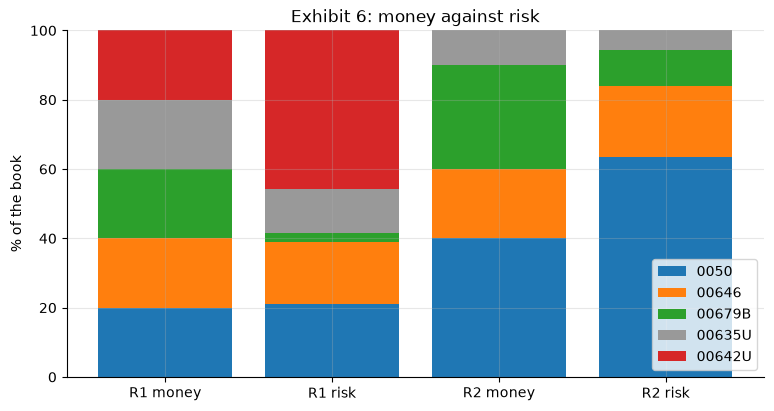

In [8]:
sp1, b1, m1, rc1, sh1 = split(SA, w1)
tab = pl.DataFrame({"fund": FUNDS, "A cov(R_i,R_p) %^2": np.round(1e4 * SA @ w1, 2), "beta": np.round(b1, 3),
                    "MRC %": np.round(100 * m1, 2), "RC points": np.round(100 * rc1, 2),
                    "Euler share %": np.round(100 * sh1, 1),
                    "stand-alone %": np.round(100 * w1 * vol / float(w1 @ vol), 1),
                    "variance term %": np.round(100 * w1**2 * vol**2 / sp1**2, 3)})
print(tab)
print(f"sum of RC {100 * rc1.sum():.4f} = s_p {100 * sp1:.4f}; sum of shares {sh1.sum():.15f}")
show("00642U's share, %", 100 * sh1[J["00642U"]], ".1f", "45.9")
show("00679B's share, %", 100 * sh1[J["00679B"]], ".1f", "2.6")
rp = X @ w1
slopes = np.array([np.cov(w1[i] * X[:, i], rp, ddof=0)[0, 1] / rp.var() for i in range(5)])
print(f"largest |OLS slope - share| {np.abs(slopes - sh1).max():.1e}")
dlt = np.array([0, 0, 0.05, 0, -0.05])
v_new = sp1**2 + 2 * float(dlt @ SA @ w1) + float(dlt @ SA @ dlt)
show("switch: linear, points", 100 * float(dlt @ m1), ".2f", "-1.24")
show("switch: exact, points", 100 * (math.sqrt(v_new) - sp1), ".2f", "-1.10")
show("switch: new s_p, %", 100 * math.sqrt(v_new), ".2f", "10.39")
sp2, b2, _, _, sh2 = split(SA, w2)
show("R2: 0050's beta", b2[0], ".3f", "1.587")
show("R2: 0050's share, %", 100 * sh2[0], ".1f", "63.5")
# the widget's daily matrix is A S to ten decimals: its first draw
spw, _, _, _, shw = split(np.round(SA, 10), w1)
print(f"widget's first draw: s_p {100 * spw:.2f}%, shares {np.round(100 * shw, 1)}")

fig, ax = plt.subplots()
bars = {"R1 money": w1, "R1 risk": sh1, "R2 money": w2, "R2 risk": sh2}
bottom = np.zeros(4)
for j, s in enumerate(FUNDS):
    v_ = np.array([b[j] for b in bars.values()])
    ax.bar(list(bars), 100 * v_, bottom=100 * bottom, label=s, color="0.6" if s == "00635U" else None)
    bottom += v_
ax.set_ylabel("% of the book")
ax.set_title("Exhibit 6: money against risk")
ax.legend()
plt.show()

## Part 7 — R1's shares in the 92 windows (Exhibit 7, Example 9)

Each signal reads the trailing 504 rows of the estimation frame through a month's last session; the signal dates are those of the targets file. The window's covariance is annualized with the full sample's $A$. A negative share is counted with the guard `1e-12`.

windows: 92   [book: 92]
00642U's lowest share, %: 32.7   [book: 32.7]
00642U's highest share, %: 54.3   [book: 54.3]
00679B negative in 22 windows, 2019-05-31 .. 2022-04-29 (36 windows); the last -0.0023%
window 2018-01-29 .. 2020-02-27: s_p 8.13%, MRC [ 8.76  8.1  -0.77  2.47 22.07]
00679B's beta to the book: -0.0944   [book: -0.0944]
00679B's share, %: -1.89   [book: -1.89]
after the switch, %: 7.07   [book: 7.07]


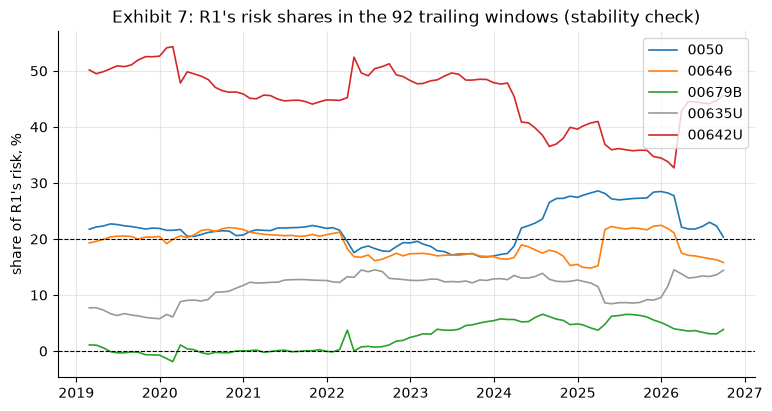

In [9]:
sig = tg.filter(pl.col("rule") == pl.lit("R1")).sort("trade")["signal"].to_list()
n_rows = [sum(1 for dd in edates if dd <= s) for s in sig]
SHW = np.array([split(A * cov0(X[n - WINDOW:n]), w1)[4] for n in n_rows])
show("windows", len(sig), "d", "92")
show("00642U's lowest share, %", 100 * SHW[:, 4].min(), ".1f", "32.7")
show("00642U's highest share, %", 100 * SHW[:, 4].max(), ".1f", "54.3")
neg = [k for k in range(len(sig)) if SHW[k, J["00679B"]] < -EPS]
print(f"00679B negative in {len(neg)} windows, {sig[neg[0]]} .. {sig[neg[-1]]} "
      f"({neg[-1] - neg[0] + 1} windows); the last {100 * SHW[neg[-1], J['00679B']]:.4f}%")
k = sig.index("2020-02-27")
n = n_rows[k]
Sn = A * cov0(X[n - WINDOW:n])
spn, bn, mn, _, shn = split(Sn, w1)
print(f"window {edates[n - WINDOW]} .. {edates[n - 1]}: s_p {100 * spn:.2f}%, MRC {np.round(100 * mn, 2)}")
show("00679B's beta to the book", bn[J["00679B"]], ".4f", "-0.0944")
show("00679B's share, %", 100 * shn[J["00679B"]], ".2f", "-1.89")
show("after the switch, %", 100 * math.sqrt(float((w1 + dlt) @ Sn @ (w1 + dlt))), ".2f", "7.07")

fig, ax = plt.subplots()
ds = [date.fromisoformat(s) for s in sig]
for s in FUNDS:
    ax.plot(ds, 100 * SHW[:, J[s]], lw=1.2, label=s, color="0.6" if s == "00635U" else None)
ax.axhline(0, ls="--", c="k", lw=0.8)
ax.axhline(20, ls="--", c="k", lw=0.8)
ax.set_ylabel("share of R1's risk, %")
ax.set_title("Exhibit 7: R1's risk shares in the 92 trailing windows (stability check)")
ax.legend()
plt.show()

## Part 8 — U28's factor split (Example 10, Exhibit 8)

The sector closes are repaired as in LM23's lab: every close listed in `sectors_close_repairs.csv` is replaced by its official 13:30:00 value, and dropped when the value is missing (FinMind's free plan); U28's numbers then differ slightly and the cell says so. The market model (23.1) with an intercept is fitted to each sector on the TAIEX price index; (27.8) splits the equal-weight book's variance.

In [10]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None, schema_overrides={"date": pl.String})
raw = raw.sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"date": pl.String, "close_1330": pl.Float64})
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g_ = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                         pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g_, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
FULL_DATA = int(rep["close_1330"].is_not_null().sum()) == rep.height
U28 = [c for c in raw.columns if c not in ("date", "TAIEX", "Electronic", "ChemicalBiotechnologyMedicalCare")]
keep = ["TAIEX", *U28]
cl = fixed.filter(pl.col("date").is_between(pl.lit("2008-12-01"), pl.lit(LAST))).sort("date")
ret = (cl.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in keep]).slice(1)
         .filter(pl.all_horizontal([pl.col(c).is_not_null() for c in keep])))
U, M = ret.select(U28).to_numpy(), ret["TAIEX"].to_numpy()
Tu = len(M)
Au = Tu / ((date.fromisoformat(LAST) - date.fromisoformat("2008-12-01")).days / 365.25)
print(f"full data: {FULL_DATA}; T = {Tu}, A = {Au:.4f}")
mc = M - M.mean()
vm = float(mc @ mc) / Tu
beta = (U - U.mean(axis=0)).T @ mc / Tu / vm
E = U - (U.mean(axis=0) - beta * M.mean()) - np.outer(M, beta)
wu = np.full(28, 1 / 28)
Su, Sres = cov0(U), cov0(E)
vp, bp = float(wu @ Su @ wu), float(wu @ beta)
v_sys, v_res = bp**2 * vm, float(wu @ Sres @ wu)
v_diag = float((wu**2 * np.diag(Sres)).sum())
show("book's volatility, %", 100 * math.sqrt(Au * vp), ".2f", "15.75", u28=True)
show("book's beta", bp, ".3f", "0.807", u28=True)
show("systematic share, %", 100 * v_sys / vp, ".3f", "83.426", u28=True)
show("R-squared of the book on TAIEX, %", 100 * np.corrcoef(U @ wu, M)[0, 1] ** 2, ".3f", "83.426", u28=True)
show("residual variances, %", 100 * v_diag / vp, ".3f", "4.037", u28=True)
show("residual covariances, %", 100 * (v_res - v_diag) / vp, ".3f", "12.537", u28=True)
show("residual covariances set to 0, %", 100 * math.sqrt(Au * (v_sys + v_diag)), ".2f", "14.73", u28=True)
rc_u = wu * (Su @ wu) / math.sqrt(vp)
rc_sys, rc_res = wu * beta * bp * vm / math.sqrt(vp), wu * (Sres @ wu) / math.sqrt(vp)
ks = U28.index("Semiconductor")
print(f"Semiconductor: {100 * rc_u[ks] / math.sqrt(vp):.2f}% = {100 * rc_sys[ks] / math.sqrt(vp):.2f}% + "
      f"{100 * rc_res[ks] / math.sqrt(vp):.2f}%")
Cr = np.corrcoef(E, rowvar=False)
show("mean residual correlation", float(Cr[np.triu_indices(28, 1)].mean()), ".3f", "0.112", u28=True)
volu = np.sqrt(Au * np.diag(Su))
show("ratio (27.7) of the U28 book", volu.mean() / math.sqrt(Au * vp), ".3f", "1.393", u28=True)
# LM9's buy-and-hold mix of Semiconductor and FinancialInsurance from the close of 2008-12-01
gs, gf = np.cumprod(1 + U[:, ks]), np.cumprod(1 + U[:, U28.index("FinancialInsurance")])
show("LM9's drift: Semiconductor's weight at the end", (gs / (gs + gf))[-1], ".3f", "0.858", u28=True)

full data: True; T = 4382, A = 245.4794
book's volatility, %: 15.75   [book: 15.75]
book's beta: 0.807   [book: 0.807]
systematic share, %: 83.426   [book: 83.426]
R-squared of the book on TAIEX, %: 83.426   [book: 83.426]
residual variances, %: 4.037   [book: 4.037]
residual covariances, %: 12.537   [book: 12.537]
residual covariances set to 0, %: 14.73   [book: 14.73]
Semiconductor: 3.82% = 4.46% + -0.64%
mean residual correlation: 0.112   [book: 0.112]
ratio (27.7) of the U28 book: 1.393   [book: 1.393]
LM9's drift: Semiconductor's weight at the end: 0.858   [book: 0.858]


## Part 9 — Practice problems 10, 11 and 12, and the module's code block

**Problem 10** uses Problem 4's constructed inputs with annual means of 8%, 4% and 10%. **Problem 11** is Parts 1 and 4; **Problem 12** is Part 3, whose printout gives the largest difference from the net wealth path, Exhibit 3's trade and, in Part 7, the shares of Exhibit 7.

In [11]:
sd3 = np.array([0.20, 0.10, 0.30])
C3 = np.array([[1, 0.2, 0.6], [0.2, 1, -0.2], [0.6, -0.2, 1]])
S3 = C3 * np.outer(sd3, sd3)
w3, mu3 = np.array([0.4, 0.4, 0.2]), np.array([0.08, 0.04, 0.10])
sp3, _, m3, rc3, sh3 = split(S3, w3)
show("P10: mu_p, %", 100 * float(w3 @ mu3), ".2f", "6.80")
show("P10: sigma_p, %", 100 * sp3, ".2f", "13.30")
show("P10: ratio (27.7)", float(w3 @ sd3) / sp3, ".2f", "1.35")
print("P10: shares, %", np.round(100 * sh3, 1), "| MRC, %", np.round(100 * m3, 2), "| RC, points", np.round(100 * rc3, 3))
d3 = np.array([0, 0.05, -0.05])
show("P10: linear change, points", 100 * float(d3 @ m3), ".2f", "-0.96")
v3 = sp3**2 + 2 * float(d3 @ S3 @ w3) + float(d3 @ S3 @ d3)                       # (10.9)
show("P10: exact change by (10.9), points", 100 * (math.sqrt(v3) - sp3), ".2f", "-0.89")
show("P10: new sigma_p, %", 100 * math.sqrt(v3), ".2f", "12.41")
print("P11: frames rebuilt in Part 1; of the five pairs only 00679B-00642U's daily-monthly gap reaches two monthly "
      "normal-theory SEs (Part 4)")
print(f"P12: largest |difference| from R1's net wealth path "
      f"{float(np.abs(net.filter(pl.col('rule') == pl.lit('R1')).sort('date')['wealth'].to_numpy() - paths['R1'][1]).max()):.1e}")

P10: mu_p, %: 6.80   [book: 6.80]
P10: sigma_p, %: 13.30   [book: 13.30]
P10: ratio (27.7): 1.35   [book: 1.35]
P10: shares, % [56.1 10.  33.9] | MRC, % [18.65  3.31 22.56] | RC, points [7.461 1.324 4.512]
P10: linear change, points: -0.96   [book: -0.96]
P10: exact change by (10.9), points: -0.89   [book: -0.89]
P10: new sigma_p, %: 12.41   [book: 12.41]
P11: frames rebuilt in Part 1; of the five pairs only 00679B-00642U's daily-monthly gap reaches two monthly normal-theory SEs (Part 4)
P12: largest |difference| from R1's net wealth path 0.0e+00


In [12]:
# the module's code block (Section 9), as printed
funds = ["0050", "00646", "00679B", "00635U", "00642U"]
est = pl.read_csv("data/e5_estimation.csv",
                  schema_overrides={"fund": pl.String})
X = (est.pivot(on="fund", index="date", values="R")
     .sort("date").select(funds).to_numpy())
A = 2362 * 365.25 / 3551                       # 242.951
S = A * np.cov(X, rowvar=False, ddof=0)        # divisor T
w = np.full(5, 0.2)
sp = np.sqrt(w @ S @ w)                        # 0.11493
rc = w * (S @ w) / sp                          # (27.6)
assert abs(rc.sum() - sp) < 1e-15              # Euler's identity
d = pl.col("date").str.to_date()
wk = (est.group_by("fund", d.dt.iso_year().alias("y"),
                   d.dt.week().alias("k"))
      .agg((pl.col("R") + 1).product() - 1)   # weekly returns
      .sort("fund", "y", "k"))

def post_trade(W_pre, drift, f, tax, k=0.001425):
    W = W_pre                                  # (27.2) by iteration
    while True:
        x = W * f - W_pre * drift
        new = W_pre - k * np.abs(x).sum() - tax @ np.clip(-x, 0, None)
        if abs(new - W) < 1e-15 * W_pre:
            return new
        W = new

show("code block: s_p", float(sp), ".5f", "0.11493")
print(f"weekly rows: {wk.height}; post_trade on 1 April 2026: "
      f"{post_trade(big['W_pre'], big['drift'], big['f'], taxv) / big['W_post'] - 1:.1e} from the recursion")

code block: s_p: 0.11493   [book: 0.11493]
weekly rows: 2510; post_trade on 1 April 2026: 0.0e+00 from the recursion


## Part 10 — Extension: R2's risk shares in the 92 windows (*descriptive*, a stability check)

R2 holds 40% of its money in 0050. Repeat Part 7 for R2's fixed weights. How far does 0050's share of R2's risk move across the windows, and in how many windows does it exceed 70% (count with the guard `1e-12`)? What does that say about a fixed money mix as a risk budget? Turning risk shares into targets is LM31's subject.

In [13]:
SH2 = np.array([split(A * cov0(X[n - WINDOW:n]), w2)[4] for n in n_rows])
over = [sig[k] for k in range(len(sig)) if SH2[k, 0] > 0.70 + EPS]
print(f"0050's share of R2's risk: {100 * SH2[:, 0].min():.1f}% to {100 * SH2[:, 0].max():.1f}%, "
      f"above 70% in {len(over)} windows; its money weight is 40%")
# your code: plot SH2 as in Part 7, and compare 00679B's share with its 30% of the money

0050's share of R2's risk: 55.3% to 72.1%, above 70% in 13 windows; its money weight is 40%
